# Практическое занятие 03. Полный проект машинного обучения

Цель занятия: пройти проект машинного обучения целиком — от постановки задачи и разведочного анализа до конвейера подготовки данных, настройки модели и единственной проверки на тестовой выборке, в которую до самого конца не заглядываем.

Основа — глава 2 книги Орельена Жерона «Прикладное машинное обучение с помощью Scikit-Learn и TensorFlow», стр. 63–119. Теорию разбирали на лекции, здесь — только код.

Блокнот рассчитан на два занятия. Продолжая работу, выполните все ячейки выше места остановки (Cell → Run All Above): набор уже лежит в `data/`, а тяжёлых вычислений до раздела «Сравнение моделей» нет.

План:

- постановка задачи: регрессия, метрики RMSE и MAE — 10 мин;
- загрузка данных и первый взгляд: типы признаков, пропуски, гистограммы — 15 мин;
- тестовая выборка: случайное и стратифицированное разбиение — 15 мин;
- визуализация: географические данные, корреляции, комбинации признаков — 15 мин;
- подготовка данных: пропуски, категориальный признак, масштабирование — 15 мин;
- свой трансформер, `Pipeline` и `ColumnTransformer` — 10 мин;
- сравнение моделей и перекрёстная проверка — 15 мин;
- поиск по сетке, анализ ошибок и финальная оценка — 15 мин;
- задание: разведочный анализ и упражнения главы 2 — 35 мин.

In [1]:
import sys

import matplotlib
import numpy as np
import pandas as pd
import scipy
import sklearn

sys.version, np.__version__, pd.__version__, matplotlib.__version__, scipy.__version__, sklearn.__version__

('3.8.10 (default, Jun 22 2022, 20:18:18) \n[GCC 9.4.0]',
 '1.24.4',
 '2.0.3',
 '3.7.5',
 '1.10.1',
 '1.3.2')

In [2]:
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (8, 5)

# Постановка задачи

Книга: гл. 2, стр. 65–71.

Задача: по данным переписи Калифорнии 1990 года предсказать **медианную стоимость дома в округе** (англ. *district*, в данных — группа кварталов с населением 600–3000 человек). Прогноз модели уйдёт в следующую систему, которая решает, стоит ли инвестировать в район.

Что это за задача:

- **обучение с учителем** — у каждого округа известен ответ, медианная стоимость дома;
- **регрессия** — предсказываем число, а не класс; признаков много, поэтому это многомерная регрессия (англ. *multiple regression*);
- **пакетное обучение** — данные помещаются в память и не поступают потоком.

## Метрики качества: RMSE и MAE

Корень из среднеквадратичной ошибки (англ. *root mean squared error*, RMSE) — типичная метрика регрессии:

$$\mathrm{RMSE} = \sqrt{\frac{1}{m} \sum_{i=1}^{m} \left(\hat{y}^{(i)} - y^{(i)}\right)^2}$$

Средняя абсолютная ошибка (англ. *mean absolute error*, MAE):

$$\mathrm{MAE} = \frac{1}{m} \sum_{i=1}^{m} \left|\hat{y}^{(i)} - y^{(i)}\right|$$

Обе метрики — в единицах целевой величины (здесь — в долларах). RMSE соответствует норме $\ell_2$, MAE — норме $\ell_1$.

In [3]:
y_true = np.array([150_000, 200_000, 250_000, 300_000, 350_000])
y_pred = np.array([160_000, 190_000, 255_000, 290_000, 345_000])

errors = y_pred - y_true
errors

array([ 10000, -10000,   5000, -10000,  -5000])

In [4]:
rmse = np.sqrt(np.mean(errors ** 2))
mae = np.mean(np.abs(errors))

rmse, mae

(8366.600265340756, 8000.0)

То же самое — функциями [`sklearn.metrics`](https://scikit-learn.org/1.3/modules/model_evaluation.html#regression-metrics):

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.sqrt(mean_squared_error(y_true, y_pred)), mean_absolute_error(y_true, y_pred)

(8366.600265340756, 8000.0)

RMSE возводит ошибки в квадрат и поэтому сильнее штрафует крупные промахи: если выбросов много, MAE бывает удобнее; если крупные ошибки редки, обычно выбирают RMSE.

# Загрузка данных и первый взгляд

Книга: гл. 2, стр. 75–81.

## Загрузка

Набор лежит в репозитории книги архивом `housing.tgz`. Функция скачивает его один раз и распаковывает в `data/`; повторный запуск берёт файл с диска.

**Набор нужно скачать до занятия** — в аудитории может не быть сети.

In [6]:
import tarfile
import urllib.request
from pathlib import Path

HOUSING_URL = 'https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.tgz'


def fetch_housing_data(data_dir):
    """Скачивает и распаковывает набор данных, если его ещё нет на диске."""
    data_dir.mkdir(parents=True, exist_ok=True)
    csv_path = data_dir / 'housing.csv'
    if not csv_path.exists():
        tgz_path = data_dir / 'housing.tgz'
        urllib.request.urlretrieve(HOUSING_URL, tgz_path)
        with tarfile.open(tgz_path) as housing_tgz:
            housing_tgz.extractall(path=data_dir)
    return csv_path


housing_path = fetch_housing_data(Path('data'))
housing_path

PosixPath('data/housing.csv')

In [7]:
housing = pd.read_csv(housing_path)
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Каждая строка — один округ, столбцы — признаки:

| Признак | Что означает |
|---|---|
| `longitude`, `latitude` | долгота и широта округа |
| `housing_median_age` | медианный возраст домов |
| `total_rooms`, `total_bedrooms` | всего комнат и спален в округе |
| `population`, `households` | население и число домохозяйств |
| `median_income` | медианный доход (в десятках тысяч долларов, см. ниже) |
| `median_house_value` | **целевой признак** — медианная стоимость дома, $ |
| `ocean_proximity` | близость к океану — категориальный признак |

## Типы признаков и пропуски

In [8]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


Что видно из `info()`:

- 20 640 округов — по меркам машинного обучения набор маленький;
- в `total_bedrooms` только 20 433 непустых значения — у 207 округов признак пропущен;
- все признаки числовые, кроме `ocean_proximity` (тип `object`).

In [9]:
housing.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Категориальный признак — смотрим, какие значения он принимает и как часто:

In [10]:
housing['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

Числовые признаки — сводка `describe()`: пропуски при подсчёте статистик игнорируются.

In [11]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## Гистограммы

Гистограмма показывает, сколько округов попало в каждый интервал значений признака.

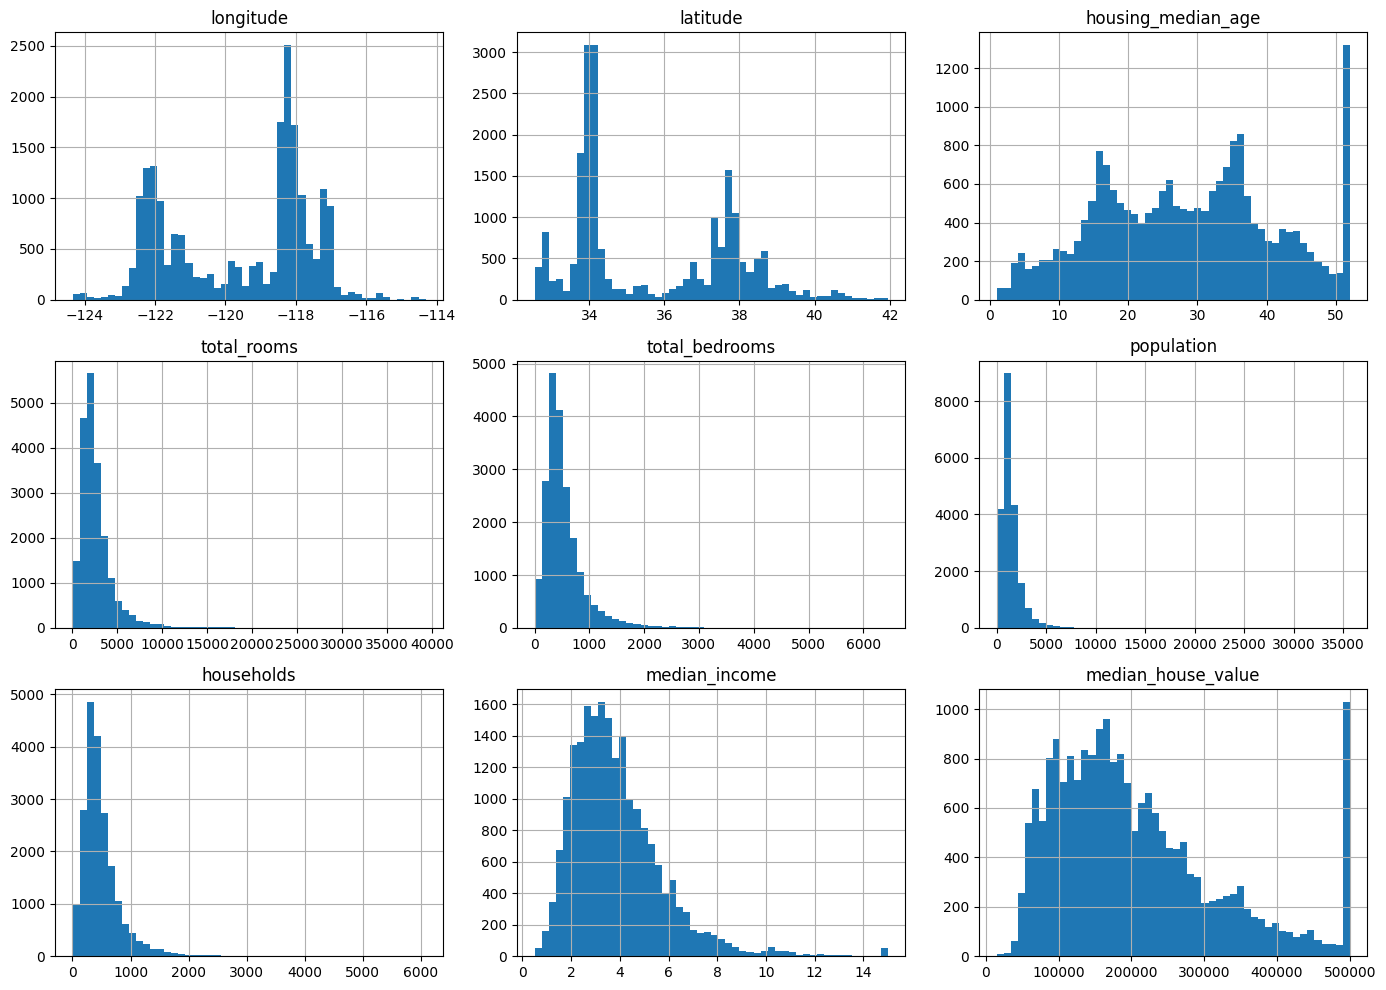

In [12]:
housing.hist(bins=50, figsize=(14, 10))
plt.tight_layout()
plt.show()

На что обратить внимание (книга, стр. 80):

- `median_income` — не в долларах: значения масштабированы (примерно десятки тысяч долларов) и ограничены сверху 15 и снизу 0.5;
- `housing_median_age` и `median_house_value` **ограничены сверху** — справа видны высокие столбики-«пики». Для целевого признака это важно: модель может выучить, что цена никогда не превышает $500 000;
- масштабы признаков очень разные — это понадобится при подготовке данных;
- у многих гистограмм «тяжёлый хвост» вправо.

In [13]:
(housing['median_house_value'] > 500_000).sum(), housing['median_house_value'].max()

(965, 500001.0)

# Тестовая выборка

Книга: гл. 2, стр. 81–86.

Тестовую (испытательную) выборку откладывают **сразу**, до любого анализа, и не смотрят на неё до самого конца проекта. Если разглядывать все данные, мозг заметит закономерности и в тестовой части, мы бессознательно подстроим под них модель, и оценка на тесте окажется слишком оптимистичной. Это называется **смещением из-за подглядывания в данные** (англ. *data snooping bias*).

## Случайное разбиение: [`train_test_split`](https://scikit-learn.org/1.3/modules/generated/sklearn.model_selection.train_test_split.html)

Функция перемешивает строки и отрезает 20 % под тест:

In [14]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)
len(train_set), len(test_set)

(16512, 4128)

Без фиксированного `random_state` каждый запуск даёт новую тестовую выборку — и за несколько запусков модель «увидит» весь набор. С `random_state` разбиение воспроизводимо, но сломается, когда в набор добавят новые строки. Устойчивое решение — решать «тест или нет» по хешу идентификатора строки (книга, стр. 82–83).

## Стратифицированное разбиение

Случайное разбиение хорошо на больших наборах. На маленьких оно может исказить пропорции важных групп — как случайная выборка из 1000 опрошенных может случайно содержать 60 % мужчин при 51 % в населении.

**Стратификация** (англ. *stratified sampling*): делим данные на однородные группы — **страты** — и берём из каждой страты одну и ту же долю.

Предположим, что медианный доход — важный признак для прогноза цены. Тогда тестовая выборка должна повторять распределение дохода. Доход непрерывен, поэтому сначала разбиваем его на 5 категорий:

In [15]:
housing['income_cat'] = pd.cut(
    housing['median_income'],
    bins=[0.0, 1.5, 3.0, 4.5, 6.0, np.inf],
    labels=[1, 2, 3, 4, 5],
)

housing['income_cat'].value_counts().sort_index()

income_cat
1     822
2    6581
3    7236
4    3639
5    2362
Name: count, dtype: int64

Параметр `stratify` функции `train_test_split` делает разбиение стратифицированным:

In [16]:
strat_train_set, strat_test_set = train_test_split(
    housing,
    test_size=0.2,
    stratify=housing['income_cat'],
    random_state=42,
)

Сравним доли категорий дохода во всём наборе, в стратифицированной и в случайной тестовой выборке:

In [17]:
def income_cat_proportions(data):
    return data['income_cat'].value_counts(normalize=True).sort_index()


_, random_test_set = train_test_split(housing, test_size=0.2, random_state=42)

proportions = pd.DataFrame({
    'overall': income_cat_proportions(housing),
    'stratified': income_cat_proportions(strat_test_set),
    'random': income_cat_proportions(random_test_set),
})
proportions['random_error_%'] = 100 * (proportions['random'] / proportions['overall'] - 1)
proportions['stratified_error_%'] = 100 * (proportions['stratified'] / proportions['overall'] - 1)
proportions.round(4)

,overall,stratified,random,random_error_%,stratified_error_%
income_cat,,,,,
1,0.0398,0.0400,0.0402,0.9732,0.3650
2,0.3188,0.3188,0.3244,1.7323,-0.0152
3,0.3506,0.3505,0.3585,2.2664,-0.0138
4,0.1763,0.1764,0.1674,-5.0563,0.0275
5,0.1144,0.1143,0.1095,-4.3184,-0.0847


У стратифицированной выборки отклонение долей от всего набора близко к нулю, у случайной — заметно больше.

Категория дохода нужна была только для разбиения — удаляем её из обеих частей:

In [18]:
strat_train_set = strat_train_set.drop(columns='income_cat')
strat_test_set = strat_test_set.drop(columns='income_cat')
housing = housing.drop(columns='income_cat')
strat_train_set.columns.tolist()

['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income',
 'median_house_value',
 'ocean_proximity']

**С этого момента работаем только с `strat_train_set`.** `strat_test_set` понадобится один раз — один раз в самом конце проекта — в разделе «Финальная оценка на тестовой выборке».

# Визуализация и поиск закономерностей

Книга: гл. 2, стр. 87–94.

Исследуем копию обучающей выборки, чтобы случайно её не испортить:

In [19]:
housing = strat_train_set.copy()
housing.shape

(16512, 10)

## Географические данные

У каждого округа есть координаты — нарисуем их точками: размер точки — население округа, цвет — медианная стоимость дома. Полупрозрачность `alpha` проявляет места высокой плотности: районы Сан-Франциско, Лос-Анджелеса и Сан-Диего, долину Центральной Калифорнии.

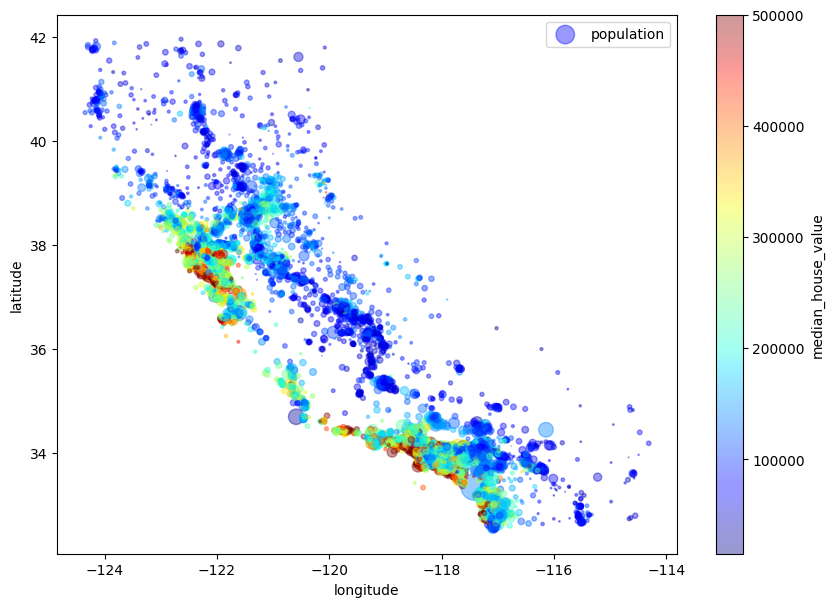

In [20]:
housing.plot(
    kind='scatter',
    x='longitude',
    y='latitude',
    alpha=0.4,
    s=housing['population'] / 100,
    label='population',
    c='median_house_value',
    cmap='jet',
    colorbar=True,
    figsize=(10, 7),
)
plt.legend()
plt.show()

Цена сильно зависит от расположения (у океана дороже) и от плотности населения. Признак «расстояние до ближайшего крупного города» мог бы помочь модели.

## Корреляции

Стандартный коэффициент корреляции (коэффициент Пирсона) лежит в диапазоне от −1 до 1 и измеряет только **линейную** связь: близко к 1 — сильная прямая связь, к −1 — сильная обратная, к 0 — линейной связи нет. Нелинейную связь он не видит.

In [21]:
corr_matrix = housing.corr(numeric_only=True)
corr_matrix['median_house_value'].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.687151
total_rooms           0.135140
housing_median_age    0.114146
households            0.064590
total_bedrooms        0.047781
population           -0.026882
longitude            -0.047466
latitude             -0.142673
Name: median_house_value, dtype: float64

Сильнее всего цена связана с медианным доходом — посмотрим на их диаграмму рассеяния:

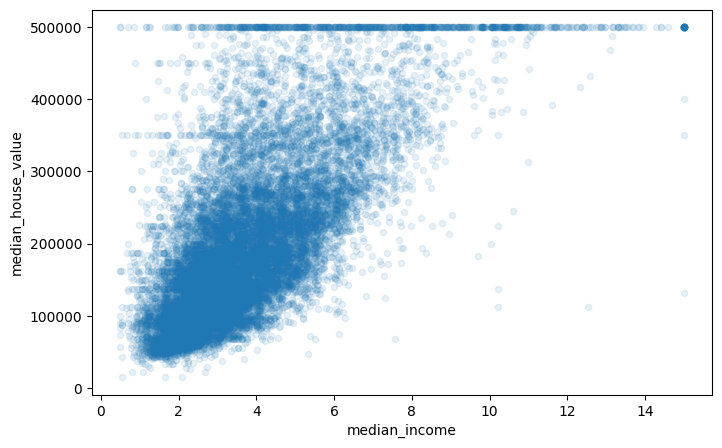

In [22]:
housing.plot(kind='scatter', x='median_income', y='median_house_value', alpha=0.1)
plt.show()

Связь сильная и с восходящим трендом. Хорошо видна горизонтальная линия на $500 000 — это ограничение цены сверху; менее заметные линии есть около $450 000, $350 000 и $280 000. Такие округа модель может «выучить» как особенность данных — их стоит удалить или помнить о них.

## Комбинации признаков

Сами по себе «всего комнат в округе» и «всего спален» мало что говорят — они зависят от размера округа. Полезнее относительные величины:

In [23]:
housing['rooms_per_household'] = housing['total_rooms'] / housing['households']
housing['bedrooms_per_room'] = housing['total_bedrooms'] / housing['total_rooms']
housing['population_per_household'] = housing['population'] / housing['households']

corr_matrix = housing.corr(numeric_only=True)
corr_matrix['median_house_value'].sort_values(ascending=False)

median_house_value          1.000000
median_income               0.687151
rooms_per_household         0.146255
total_rooms                 0.135140
housing_median_age          0.114146
households                  0.064590
total_bedrooms              0.047781
population_per_household   -0.021991
population                 -0.026882
longitude                  -0.047466
latitude                   -0.142673
bedrooms_per_room          -0.259952
Name: median_house_value, dtype: float64

Новый признак `bedrooms_per_room` коррелирует с ценой сильнее, чем `total_rooms` и `total_bedrooms`: чем меньше доля спален среди комнат, тем дороже дом. `rooms_per_household` тоже информативнее, чем `total_rooms`.

Разведочный анализ не обязан быть исчерпывающим: цель — быстро получить представление о данных и гипотезы для первого прототипа. Потом к анализу возвращаются, глядя на ошибки модели.

# Подготовка данных: пропуски, категории, масштабирование

Книга: гл. 2, стр. 94–104.

Подготовку пишем функциями и классами, а не правим таблицу руками: тогда её можно повторить на тестовой выборке, на свежих данных в рабочей системе и перебирать её варианты автоматически.

Начинаем с чистой копии обучающей выборки и отделяем признаки от меток — преобразования для них разные (стр. 95):

In [24]:
housing = strat_train_set.drop(columns='median_house_value')
housing_labels = strat_train_set['median_house_value'].copy()

housing.shape, housing_labels.shape

((16512, 9), (16512,))

## Пропуски

Большинство алгоритмов не умеет работать с пропусками, а в `total_bedrooms` они есть:

In [25]:
housing.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        158
population              0
households              0
median_income           0
ocean_proximity         0
dtype: int64

In [26]:
sample_incomplete_rows = housing[housing.isna().any(axis=1)].head()
sample_incomplete_rows

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
1606,-122.08,37.88,26.0,2947.0,NaN,825.0,626.0,2.9330,NEAR BAY
10915,-117.87,33.73,45.0,2264.0,NaN,1970.0,499.0,3.4193,<1H OCEAN
19150,-122.70,38.35,14.0,2313.0,NaN,954.0,397.0,3.7813,<1H OCEAN
4186,-118.23,34.13,48.0,1308.0,NaN,835.0,294.0,4.2891,<1H OCEAN
16885,-122.40,37.58,26.0,3281.0,NaN,1145.0,480.0,6.3580,NEAR OCEAN


Три пути (стр. 95). Первый — удалить округа с пропусками:

In [27]:
sample_incomplete_rows.dropna(subset=['total_bedrooms'])

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity


Второй — удалить весь признак:

In [28]:
sample_incomplete_rows.drop(columns='total_bedrooms')

,longitude,latitude,housing_median_age,total_rooms,population,households,median_income,ocean_proximity
1606,-122.08,37.88,26.0,2947.0,825.0,626.0,2.9330,NEAR BAY
10915,-117.87,33.73,45.0,2264.0,1970.0,499.0,3.4193,<1H OCEAN
19150,-122.70,38.35,14.0,2313.0,954.0,397.0,3.7813,<1H OCEAN
4186,-118.23,34.13,48.0,1308.0,835.0,294.0,4.2891,<1H OCEAN
16885,-122.40,37.58,26.0,3281.0,1145.0,480.0,6.3580,NEAR OCEAN


Третий — заполнить пропуски значением, например медианой обучающей выборки:

In [29]:
median = housing['total_bedrooms'].median()

sample_incomplete_rows.fillna({'total_bedrooms': median})

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
1606,-122.08,37.88,26.0,2947.0,433.0,825.0,626.0,2.9330,NEAR BAY
10915,-117.87,33.73,45.0,2264.0,433.0,1970.0,499.0,3.4193,<1H OCEAN
19150,-122.70,38.35,14.0,2313.0,433.0,954.0,397.0,3.7813,<1H OCEAN
4186,-118.23,34.13,48.0,1308.0,433.0,835.0,294.0,4.2891,<1H OCEAN
16885,-122.40,37.58,26.0,3281.0,433.0,1145.0,480.0,6.3580,NEAR OCEAN


Медиану нужно **запомнить**: тем же значением заполняют пропуски в тестовой выборке и в новых данных после запуска системы.

## [`SimpleImputer`](https://scikit-learn.org/1.3/modules/generated/sklearn.impute.SimpleImputer.html)

Заполнение пропусков (англ. *imputation*) в scikit-learn делает `SimpleImputer` (в книге — класс `Imputer`, его давно убрали из библиотеки). Медиана считается только по числам, поэтому текстовый признак временно убираем:

In [30]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')
housing_num = housing.drop(columns='ocean_proximity')
imputer.fit(housing_num)

SimpleImputer(strategy='median')

`fit` посчитал медиану **каждого** числового признака — пропуски в новых данных могут появиться где угодно:

In [31]:
imputer.statistics_

array([-118.51   ,   34.26   ,   29.     , 2119.     ,  433.     ,
       1164.     ,  408.     ,    3.54155])

In [32]:
housing_num.median().to_numpy()

array([-118.51   ,   34.26   ,   29.     , 2119.     ,  433.     ,
       1164.     ,  408.     ,    3.54155])

`transform` заполняет пропуски выученными медианами и возвращает массив NumPy:

In [33]:
housing_num_filled = imputer.transform(housing_num)

type(housing_num_filled), housing_num_filled.shape

(numpy.ndarray, (16512, 8))

In [34]:
housing_tr = pd.DataFrame(housing_num_filled, columns=housing_num.columns, index=housing_num.index)
housing_tr.loc[sample_incomplete_rows.index, ['total_bedrooms']]

,total_bedrooms
1606,433.0
10915,433.0
19150,433.0
4186,433.0
16885,433.0


## Как устроен API scikit-learn

Все классы библиотеки играют одну из трёх ролей (стр. 97–98):

| Роль | Методы | Примеры |
|---|---|---|
| оценщик (англ. *estimator*) — оценивает параметры по данным | `fit` | `SimpleImputer`, `LinearRegression` |
| трансформер (англ. *transformer*, в переводе книги — «трансформатор») — ещё и преобразует данные | `transform`, `fit_transform` | `SimpleImputer`, `StandardScaler` |
| предиктор (англ. *predictor*) — предсказывает | `predict`, `score` | `LinearRegression`, `RandomForestRegressor` |

Гиперпараметры задаются в конструкторе и доступны как атрибуты без подчёркивания, выученные параметры — с подчёркиванием в конце:

In [35]:
imputer.strategy, imputer.n_features_in_, imputer.feature_names_in_[:3]

('median',
 8,
 array(['longitude', 'latitude', 'housing_median_age'], dtype=object))

## Категориальный признак

`ocean_proximity` — текст, медиану от него не посчитать, а модели ждут числа.

In [36]:
housing_cat = housing[['ocean_proximity']]
housing_cat.head()

,ocean_proximity
12655,INLAND
15502,NEAR OCEAN
2908,INLAND
14053,NEAR OCEAN
20496,<1H OCEAN


### Порядковое кодирование: [`OrdinalEncoder`](https://scikit-learn.org/1.3/modules/generated/sklearn.preprocessing.OrdinalEncoder.html)

Порядковое кодирование (англ. *ordinal encoding*) заменяет каждую категорию её номером (в книге — `factorize` из pandas):

In [37]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()
housing_cat_encoded = ordinal_encoder.fit_transform(housing_cat)
housing_cat_encoded[:5].ravel()

array([1., 4., 1., 4., 0.])

In [38]:
dict(enumerate(ordinal_encoder.categories_[0]))

{0: '<1H OCEAN', 1: 'INLAND', 2: 'ISLAND', 3: 'NEAR BAY', 4: 'NEAR OCEAN'}

**Ловушка**: модель решит, что категории 0 и 1 похожи сильнее, чем 0 и 4. А по смыслу `<1H OCEAN` (0) и `NEAR OCEAN` (4) как раз близки — порядка у этих категорий нет.

### Унитарное кодирование: [`OneHotEncoder`](https://scikit-learn.org/1.3/modules/generated/sklearn.preprocessing.OneHotEncoder.html)

Унитарное кодирование (англ. *one-hot encoding*, в переводе книги — «кодирование с одним активным состоянием») заводит по двоичному признаку на категорию. `OneHotEncoder` в актуальном scikit-learn принимает текст напрямую — роль `CategoricalEncoder` из книги перешла к нему.

In [39]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder()
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
housing_cat_1hot

<16512x5 sparse matrix of type '<class 'numpy.float64'>'
	with 16512 stored elements in Compressed Sparse Row format>

Результат — разреженная матрица (англ. *sparse matrix*) SciPy: хранятся только позиции единиц. Обычный массив — методом `toarray()`:

In [40]:
housing_cat_1hot.toarray()[:5]

array([[0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 1.],
       [0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.]])

In [41]:
cat_encoder.get_feature_names_out()

array(['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND',
       'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
       'ocean_proximity_NEAR OCEAN'], dtype=object)

Новая категория, которой не было при обучении, по умолчанию — ошибка:

In [42]:
new_district = pd.DataFrame({'ocean_proximity': ['DESERT']})

try:
    cat_encoder.transform(new_district)
except ValueError as error:
    print(error)

Found unknown categories ['DESERT'] in column 0 during transform


С `handle_unknown='ignore'` неизвестная категория кодируется строкой нулей. Это пригодится в перекрёстной проверке: редкая категория `ISLAND` (несколько округов) может не попасть в обучающие блоки.

In [43]:
OneHotEncoder(handle_unknown='ignore').fit(housing_cat).transform(new_district).toarray()

array([[0., 0., 0., 0., 0.]])

In [44]:
housing_cat.value_counts()

ocean_proximity
<1H OCEAN          7277
INLAND             5262
NEAR OCEAN         2124
NEAR BAY           1847
ISLAND                2
Name: count, dtype: int64

## [Масштабирование признаков](https://scikit-learn.org/1.3/modules/preprocessing.html#scaling-features-to-a-range)

Масштабы признаков очень разные, а большинство алгоритмов от этого работают хуже (стр. 103). Метки масштабировать не нужно.

In [45]:
housing_num[['total_rooms', 'median_income']].agg(['min', 'max'])

,total_rooms,median_income
min,6.0,0.4999
max,39320.0,15.0001


Масштабирование min-max (англ. *min-max scaling*, его часто называют нормализацией) сжимает значения в отрезок от 0 до 1:

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

Стандартизация (англ. *standardization*) вычитает среднее и делит на **стандартное отклонение** — в переводе книги ошибочно сказано «на дисперсию»:

$$z = \frac{x - \mu}{\sigma}$$

In [46]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

income = housing_num[['median_income']]
income_min_max = MinMaxScaler().fit_transform(income)
income_standard = StandardScaler().fit_transform(income)

(income_min_max.min(), income_min_max.max()), (income_standard.mean().round(3), income_standard.std().round(3))

((0.0, 1.0), (0.0, 1.0))

Чем методы отличаются — видно на выбросе. Добавим один ошибочный доход 100 (стр. 104) и посмотрим на размах **остальных** значений:

In [47]:
income_with_outlier = pd.concat([income, pd.DataFrame({'median_income': [100.0]})], ignore_index=True)
outlier_min_max = MinMaxScaler().fit_transform(income_with_outlier)[:-1]
outlier_standard = StandardScaler().fit_transform(income_with_outlier)[:-1]

pd.DataFrame(
    {
        'без выброса': [np.ptp(income_min_max), np.ptp(income_standard)],
        'с выбросом': [np.ptp(outlier_min_max), np.ptp(outlier_standard)],
    },
    index=['min-max', 'стандартизация'],
).round(3)

,без выброса,с выбросом
min-max,1.000,0.146
стандартизация,7.612,7.086


При min-max все нормальные доходы сжались в отрезок длиной около 0,15, стандартизация почти не изменилась.

### Ловушка: `fit` на новых данных

Масштаб, как и медиану, учат **только на обучающей выборке**. Новые данные часто приходят по одному округу — и `fit_transform` на них даёт бессмыслицу:

In [48]:
income_scaler = StandardScaler().fit(income)
new_income = strat_test_set[['median_income']].head(1)

StandardScaler().fit_transform(new_income)  # Неправильно: свой масштаб на одном округе

array([[0.]])

In [49]:
income_scaler.transform(new_income)  # Правильно: масштаб обучающей выборки

array([[2.31286606]])

# Свой трансформер, `Pipeline` и `ColumnTransformer`

Книга: гл. 2, стр. 102–106. Документация: [разработка своих оценщиков](https://scikit-learn.org/1.3/developers/develop.html).

## Свой трансформер

scikit-learn полагается на утиную типизацию (англ. *duck typing*): трансформер — любой класс с методами `fit` (возвращает `self`) и `transform`. Базовый класс `TransformerMixin` добавляет `fit_transform`, `BaseEstimator` — `get_params` и `set_params`, нужные для автоматического подбора гиперпараметров.

Трансформер добавляет комбинации признаков из раздела «Комбинации признаков». Метод `get_feature_names_out` сообщает имена добавленных столбцов — по ним конвейер назовёт все признаки:

In [50]:
from sklearn.base import BaseEstimator, TransformerMixin

ROOMS_INDEX, BEDROOMS_INDEX, POPULATION_INDEX, HOUSEHOLDS_INDEX = 3, 4, 5, 6


class CombinedAttributesAdder(BaseEstimator, TransformerMixin):
    def __init__(self, add_bedrooms_per_room=True):  # Без *args и **kwargs: иначе get_params не найдёт параметры
        self.add_bedrooms_per_room = add_bedrooms_per_room

    def fit(self, features, labels=None):
        return self  # Учить нечего

    def transform(self, features):
        rooms_per_household = features[:, ROOMS_INDEX] / features[:, HOUSEHOLDS_INDEX]
        population_per_household = features[:, POPULATION_INDEX] / features[:, HOUSEHOLDS_INDEX]
        if self.add_bedrooms_per_room:
            bedrooms_per_room = features[:, BEDROOMS_INDEX] / features[:, ROOMS_INDEX]
            return np.c_[features, rooms_per_household, population_per_household, bedrooms_per_room]
        return np.c_[features, rooms_per_household, population_per_household]

    def get_feature_names_out(self, input_features=None):
        added_names = ['rooms_per_household', 'population_per_household']
        if self.add_bedrooms_per_room:
            added_names.append('bedrooms_per_room')
        return np.array([*input_features, *added_names], dtype=object)

Гиперпараметром можно сделать любой шаг подготовки, в котором нет уверенности, — тогда поиск гиперпараметров проверит оба варианта сам (стр. 103).

## [`Pipeline`](https://scikit-learn.org/1.3/modules/generated/sklearn.pipeline.Pipeline.html)

Конвейер (англ. *pipeline*) — последовательность пар «имя — оценщик», где все шаги, кроме последнего, — трансформеры. `fit` конвейера вызывает `fit_transform` каждого шага по очереди и `fit` последнего.

In [51]:
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('attribs_adder', CombinedAttributesAdder()),
    ('std_scaler', StandardScaler()),
])
housing_num_tr = num_pipeline.fit_transform(housing_num)
housing_num_tr.shape

(16512, 11)

## [`ColumnTransformer`](https://scikit-learn.org/1.3/modules/generated/sklearn.compose.ColumnTransformer.html)

Числовые и категориальные столбцы обрабатываются по-разному. В книге для этого написан свой `DataFrameSelector` и выходы склеены `FeatureUnion`; в сноске упомянут готовившийся `ColumnTransformer` — сейчас пользуются им: каждому трансформеру — свой список столбцов.

In [52]:
from sklearn.compose import ColumnTransformer

num_attribs = housing_num.columns.tolist()
cat_attribs = ['ocean_proximity']

full_pipeline = ColumnTransformer([
    ('num', num_pipeline, num_attribs),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_attribs),  # ISLAND редка и не во всех блоках
])
housing_prepared = full_pipeline.fit_transform(housing)
housing_prepared.shape

(16512, 16)

In [53]:
full_pipeline.get_feature_names_out()

array(['num__longitude', 'num__latitude', 'num__housing_median_age',
       'num__total_rooms', 'num__total_bedrooms', 'num__population',
       'num__households', 'num__median_income',
       'num__rooms_per_household', 'num__population_per_household',
       'num__bedrooms_per_room', 'cat__ocean_proximity_<1H OCEAN',
       'cat__ocean_proximity_INLAND', 'cat__ocean_proximity_ISLAND',
       'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN'],
      dtype=object)

16 столбцов, как в книге: 8 числовых, 3 комбинации и 5 категорий. Кодировщик — с `handle_unknown='ignore'`, чтобы перекрёстная проверка не падала на редкой категории.

# Сравнение моделей и перекрёстная проверка

Книга: гл. 2, стр. 106–111.

## Оценка на обучающей выборке

После подготовки обучить модель — пара строк. Начнём с линейной регрессии:

In [54]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(housing_prepared, housing_labels)

LinearRegression()

In [55]:
some_data = housing.iloc[:5]
some_predictions = lin_reg.predict(full_pipeline.transform(some_data))

pd.DataFrame({'actual': housing_labels.iloc[:5], 'predicted': some_predictions.round()})

,actual,predicted
12655,72100.0,85658.0
15502,279600.0,305493.0
2908,82700.0,152056.0
14053,112500.0,186096.0
20496,238300.0,244551.0


In [56]:
from sklearn.metrics import mean_squared_error

lin_rmse = np.sqrt(mean_squared_error(housing_labels, lin_reg.predict(housing_prepared)))
lin_rmse

68627.87390018745

In [57]:
housing_labels.quantile([0.25, 0.5, 0.75])

0.25    119800.0
0.50    179500.0
0.75    263900.0
Name: median_house_value, dtype: float64

Ошибка около $68 000 при типичных ценах от $120 000 до $265 000 — модель **недообучена** (стр. 107). Попробуем модель мощнее — дерево решений:

In [58]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = DecisionTreeRegressor(random_state=42)
tree_reg.fit(housing_prepared, housing_labels)

tree_rmse = np.sqrt(mean_squared_error(housing_labels, tree_reg.predict(housing_prepared)))
tree_rmse

0.0

Ошибка 0 — не идеальная модель, а почти наверняка сильное **переобучение**. Оценивать модель на тех данных, на которых она училась, бессмысленно, а тест трогать нельзя.

## [Перекрёстная проверка](https://scikit-learn.org/1.3/modules/cross_validation.html)

Перекрёстная проверка по K блокам (англ. *K-fold cross-validation*) делит обучающую выборку на 10 блоков (англ. *fold*) и 10 раз учит модель на 9 из них, оценивая на оставшемся.

`cross_val_score` ждёт функцию полезности (больше — лучше), поэтому метрика — MSE со знаком минус, и перед корнем знак меняем:

In [59]:
from sklearn.model_selection import cross_val_score

tree_scores = cross_val_score(tree_reg, housing_prepared, housing_labels, scoring='neg_mean_squared_error', cv=10)
tree_rmse_scores = np.sqrt(-tree_scores)
tree_rmse_scores.round()

array([72831., 69973., 69529., 72518., 69146., 79095., 68960., 73345.,
       69826., 71077.])

In [60]:
def display_scores(scores):
    print('Оценки:', scores.round())
    print('Среднее:', scores.mean().round())
    print('Стандартное отклонение:', scores.std().round())


display_scores(tree_rmse_scores)

Оценки: [72831. 69973. 69529. 72518. 69146. 79095. 68960. 73345. 69826. 71077.]
Среднее: 71630.0
Стандартное отклонение: 2914.0


In [61]:
lin_scores = cross_val_score(lin_reg, housing_prepared, housing_labels, scoring='neg_mean_squared_error', cv=10)
lin_rmse_scores = np.sqrt(-lin_scores)
display_scores(lin_rmse_scores)

Оценки: [71763. 64115. 67771. 68635. 66846. 72528. 73997. 68802. 66443. 70140.]
Среднее: 69104.0
Стандартное отклонение: 2880.0


Дерево переобучено настолько, что проигрывает линейной регрессии. Стандартное отклонение показывает точность самой оценки — это то, чего не даёт одно отложенное разбиение.

## Случайный лес

Случайный лес (англ. *random forest*) учит много деревьев на случайных подмножествах данных и признаков и усредняет их прогнозы — это ансамблевое обучение (англ. *ensemble learning*), подробно — гл. 7 и практика 08. 30 деревьев — чтобы блокнот выполнялся быстро.

In [62]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = RandomForestRegressor(n_estimators=30, random_state=42, n_jobs=-1)
forest_reg.fit(housing_prepared, housing_labels)

forest_rmse = np.sqrt(mean_squared_error(housing_labels, forest_reg.predict(housing_prepared)))
forest_rmse

19675.288257893604

In [63]:
forest_scores = cross_val_score(forest_reg, housing_prepared, housing_labels, scoring='neg_mean_squared_error', cv=10)
forest_rmse_scores = np.sqrt(-forest_scores)
display_scores(forest_rmse_scores)

Оценки: [52271. 49544. 47688. 52481. 48809. 53389. 53484. 50935. 49692. 54714.]
Среднее: 51300.0
Стандартное отклонение: 2195.0


In [64]:
pd.DataFrame(
    {
        'train_rmse': [lin_rmse, tree_rmse, forest_rmse],
        'cv_rmse_mean': [lin_rmse_scores.mean(), tree_rmse_scores.mean(), forest_rmse_scores.mean()],
        'cv_rmse_std': [lin_rmse_scores.std(), tree_rmse_scores.std(), forest_rmse_scores.std()],
    },
    index=['LinearRegression', 'DecisionTreeRegressor', 'RandomForestRegressor'],
).round()

,train_rmse,cv_rmse_mean,cv_rmse_std
LinearRegression,68628.0,69104.0,2880.0
DecisionTreeRegressor,0.0,71630.0,2914.0
RandomForestRegressor,19675.0,51300.0,2195.0


Лес лучше всех, но ошибка на обучающей выборке намного ниже, чем на проверке, — модель всё ещё переобучена. Средства: упростить модель, регуляризовать её или собрать больше данных (стр. 110–111).

Прежде чем настраивать одну модель, стоит без долгой настройки попробовать модели разных типов и оставить 2–5 перспективных — одна из них, метод опорных векторов, в задании.

# Настройка модели и финальная оценка

Книга: гл. 2, стр. 111–117.

## [Поиск по сетке](https://scikit-learn.org/1.3/modules/generated/sklearn.model_selection.GridSearchCV.html)

Поиск по сетке (англ. *grid search*, в переводе книги — «решетчатый поиск») перебирает все комбинации заданных значений и оценивает каждую перекрёстной проверкой. Сетка из книги: 3 × 4 + 2 × 3 = 18 комбинаций по 5 блоков — 90 обучений:

In [65]:
from sklearn.model_selection import GridSearchCV

param_grid = [
    {'n_estimators': [3, 10, 30], 'max_features': [2, 4, 6, 8]},
    {'bootstrap': [False], 'n_estimators': [3, 10], 'max_features': [2, 3, 4]},
]
grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    return_train_score=True,
    n_jobs=-1,
)
grid_search.fit(housing_prepared, housing_labels)

GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid=[{'max_features': [2, 4, 6, 8],
                          'n_estimators': [3, 10, 30]},
                         {'bootstrap': [False], 'max_features': [2, 3, 4],
                          'n_estimators': [3, 10]}],
             return_train_score=True, scoring='neg_mean_squared_error')

In [66]:
grid_search.best_params_, np.sqrt(-grid_search.best_score_)

({'max_features': 8, 'n_estimators': 30}, 49898.98913455217)

Лучшая комбинация лежит **на краю сетки** — максимальные `max_features` и `n_estimators`, — значит, стоит искать дальше. Лучшая модель после поиска уже переобучена на всей обучающей выборке (`refit=True` по умолчанию):

In [67]:
grid_search.best_estimator_

RandomForestRegressor(max_features=8, n_estimators=30, random_state=42)

Оценки всех комбинаций — в `cv_results_`:

In [68]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results['rmse'] = np.sqrt(-cv_results['mean_test_score'])

cv_results[['params', 'rmse']].sort_values('rmse').head()

,params,rmse
11,"{'max_features': 8, 'n_estimators': 30}",49898.989135
8,"{'max_features': 6, 'n_estimators': 30}",49969.804416
5,"{'max_features': 4, 'n_estimators': 30}",50187.243249
17,"{'bootstrap': False, 'max_features': 4, 'n_est...",51278.378771
7,"{'max_features': 6, 'n_estimators': 10}",51519.320624


In [69]:
is_first_grid = cv_results['params'].apply(lambda params: 'bootstrap' not in params)

cv_results[is_first_grid].pivot_table(index='param_max_features', columns='param_n_estimators', values='rmse').round()

param_n_estimators,3,10,30
param_max_features,,,
2,63895.0,54916.0,52886.0
4,60075.0,52495.0,50187.0
6,58065.0,51519.0,49970.0
8,58896.0,52460.0,49899.0


Чем больше деревьев и признаков, тем меньше ошибка.

Когда комбинаций много, перебирать все слишком дорого. Тогда вместо `GridSearchCV` берут [`RandomizedSearchCV`](https://scikit-learn.org/1.3/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) — случайный поиск (англ. *randomized search*, в переводе — «рандомизированный поиск»): он оценивает заданное число `n_iter` случайных комбинаций, и бюджет вычислений задаётся явно (стр. 114). Его вы попробуете в задании 7.

## Ансамблевые методы

Объединение лучших моделей часто работает лучше любой из них, особенно если модели ошибаются по-разному (стр. 115). Ансамбли разберём в практике 08.

## Важность признаков

Дальше работаем с лучшей моделью поиска по сетке. Случайный лес оценивает важность каждого признака (англ. *feature importance*):

In [70]:
best_forest = grid_search.best_estimator_
feature_names = full_pipeline.get_feature_names_out()

feature_importances = pd.Series(best_forest.feature_importances_, index=feature_names).sort_values(ascending=False)
feature_importances.round(3)

num__median_income                 0.379
cat__ocean_proximity_INLAND        0.166
num__population_per_household      0.107
num__longitude                     0.070
num__latitude                      0.060
num__rooms_per_household           0.055
num__bedrooms_per_room             0.048
num__housing_median_age            0.042
num__population                    0.016
num__total_bedrooms                0.016
num__total_rooms                   0.015
num__households                    0.015
cat__ocean_proximity_<1H OCEAN     0.007
cat__ocean_proximity_NEAR OCEAN    0.003
cat__ocean_proximity_NEAR BAY      0.002
cat__ocean_proximity_ISLAND        0.000
dtype: float64

Главный признак — медианный доход. Из категорий `ocean_proximity` по-настоящему полезна только `INLAND`, остальные можно попробовать отбросить (стр. 116; в переводе книги смысл этой фразы искажён). Отбор признаков по важности — задание 8.

## Анализ ошибок

Прогнозы на обучающей выборке у переобученного леса слишком хороши, поэтому ошибки смотрим по прогнозам перекрёстной проверки — каждый округ предсказан моделью, которая его не видела:

In [71]:
from sklearn.model_selection import cross_val_predict

cv_predictions = cross_val_predict(best_forest, housing_prepared, housing_labels, cv=5, n_jobs=-1)

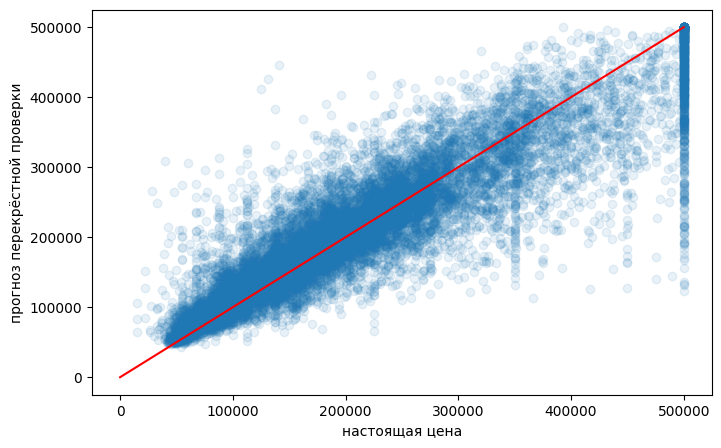

In [72]:
plt.scatter(housing_labels, cv_predictions, alpha=0.1)
plt.plot([0, 500_000], [0, 500_000], color='red')
plt.xlabel('настоящая цена')
plt.ylabel('прогноз перекрёстной проверки')
plt.show()

Модель занижает дорогие округа и завышает дешёвые. Сильнее всего занижены округа с ценой, ограниченной сверху $500 000 (видно на гистограммах): настоящая цена там выше границы. Возможные средства: удалить округа с ограниченной ценой, добавить признаки (например, расстояние до крупного города), очистить выбросы (стр. 116).

## Финальная оценка на тестовой выборке

Тест открываем **один раз**. Признаки теста проходят через подготовку методом `transform` — `fit` и `fit_transform` на тесте недопустимы:

In [73]:
final_model = grid_search.best_estimator_

test_features = strat_test_set.drop(columns='median_house_value')
test_labels = strat_test_set['median_house_value'].copy()

test_prepared = full_pipeline.transform(test_features)
final_predictions = final_model.predict(test_prepared)

final_rmse = np.sqrt(mean_squared_error(test_labels, final_predictions))
final_rmse

47873.26095812988

Здесь ошибка на тесте (около 47 900) даже чуть ниже, чем на перекрёстной проверке (около 49 900), — разница укладывается в разброс оценок по блокам. Обычно же после долгой настройки ошибка на тесте немного хуже: система подогнана к проверочным данным. Подкручивать гиперпараметры под тест нельзя — улучшение не перенесётся на новые данные (стр. 116–117).

## Единый конвейер и сохранение модели

Для работы в системе удобнее один объект: «сырые» данные на входе, прогноз на выходе. Подготовка `full_pipeline` — первый шаг конвейера, модель — последний:

In [74]:
full_model = Pipeline([
    ('preprocessing', full_pipeline),
    ('forest', RandomForestRegressor(**grid_search.best_params_, random_state=42, n_jobs=-1)),
])
full_model.fit(housing, housing_labels)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('attribs_adder',
                                                                   CombinedAttributesAdder()),
                                                                  ('std_scaler',
                                                                   StandardScaler())]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['ocean_proximity'])])),
                ('forest',
                 RandomForestRegressor(max_features=8, n_estimators=30,
                                       n_jobs=-1, random_state=42))])

In [75]:
np.allclose(full_model.predict(test_features), final_predictions)

True

Модель сохраняем на диск пакетом `joblib` и загружаем обратно; пакет ставится вместе со scikit-learn (в книге — `sklearn.externals.joblib`). В файл попадает ссылка на модуль класса `CombinedAttributesAdder`, а класс определён в блокноте (модуль `__main__`), поэтому загрузить модель можно только там, где этот класс тоже определён, — здесь, в блокноте:

In [76]:
import joblib

model_path = Path('data') / 'housing_model.joblib'
joblib.dump(full_model, model_path)

loaded_model = joblib.load(model_path)
pd.DataFrame({'actual': test_labels.head(), 'predicted': loaded_model.predict(test_features.head()).round()})

,actual,predicted
5241,500001.0,488167.0
17352,162500.0,229947.0
3505,204600.0,209950.0
7777,159700.0,166977.0
14155,184000.0,243040.0


# Задание

Задания 1–5 — разведочный анализ, они выполняются **только на обучающей выборке**. Начните с её чистой копии:

In [77]:
housing_explore = strat_train_set.copy()

### Задание 1

Сколько округов обучающей выборки имеют ограниченную сверху цену (`median_house_value` больше 500 000)? Какую долю выборки они составляют (в процентах)?

### Задание 2

Для каждой категории `ocean_proximity` посчитайте число округов, среднюю и медианную стоимость дома. Отсортируйте таблицу по медианной стоимости по убыванию. Какая категория самая дорогая и почему результату для неё стоит доверять меньше остальных?

### Задание 3

Самая простая «модель» — всегда предсказывать медиану цены обучающей выборки. Посчитайте RMSE и MAE такой модели на обучающей выборке двумя способами: формулами NumPy и функциями `sklearn.metrics`. Это нижняя планка: любая настоящая модель должна быть лучше.

### Задание 4

Придумайте свою комбинацию признаков (например, доход на человека или комнат на человека), добавьте её столбцом и посчитайте её корреляцию с `median_house_value`. Сильнее ли она связана с ценой, чем исходные признаки, из которых составлена?

### Задание 5

Сравните доли категорий `ocean_proximity` во всём наборе (обучающая и тестовая выборки вместе), в стратифицированной (по доходу) и в случайной тестовой выборке. Помогла ли стратификация по доходу сохранить пропорции и этого признака?

Подсказка: доли тестовых выборок посчитать можно — это проверка разбиения, а не анализ теста.

Задания 6–9 — по упражнениям 1–4 главы 2 (стр. 118–119). Метод опорных векторов учится медленно, поэтому заданиям 6–7 хватит подвыборки из 5000 округов обучающей выборки:

In [78]:
housing_sample = housing.sample(n=5000, random_state=42)
labels_sample = housing_labels.loc[housing_sample.index]

housing_sample.shape, labels_sample.shape

((5000, 9), (5000,))

### Задание 6

Соберите конвейер `Pipeline` из подготовки `full_pipeline` и регрессии методом опорных векторов [`SVR`](https://scikit-learn.org/1.3/modules/generated/sklearn.svm.SVR.html). Поиском по сетке на подвыборке (`cv=3`) сравните ядро `'linear'` со значениями `C` 10, 100, 1000, 10 000 и ядро `'rbf'` со значениями `C` 1000, 10 000, 100 000. Какое ядро и `C` лучше и какая RMSE? Лучшее значение на краю сетки?

Подсказка: гиперпараметр шага конвейера называется `<имя шага>__<параметр>`, например `svr__C`.

### Задание 7

Замените поиск по сетке случайным поиском [`RandomizedSearchCV`](https://scikit-learn.org/1.3/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) для ядра `'rbf'`: `C` и `gamma` берите из логарифмически равномерного распределения [`scipy.stats.loguniform`](https://docs.scipy.org/doc/scipy-1.10.1/reference/generated/scipy.stats.loguniform.html) — `C` от 1000 до 300 000, `gamma` от 0,01 до 1; `n_iter=10`, `cv=3`, `random_state=42`. Насколько изменился результат задания 6? Почему для `C` и `gamma` логарифмическая шкала удобнее равномерной?

### Задание 8

Напишите трансформер `TopFeatureSelector`, который оставляет `k` самых важных признаков по готовому массиву важностей. Добавьте его в конвейер между подготовкой и случайным лесом (`n_estimators=30`, `random_state=42`) с `k=5` и оцените конвейер перекрёстной проверкой (`cv=5`) на всей обучающей выборке. Какие признаки остались и насколько выросла ошибка по сравнению с лесом на всех признаках?

In [79]:
class TopFeatureSelector(BaseEstimator, TransformerMixin):
    def __init__(self, feature_importances, k):
        ...

    def fit(self, features, labels=None):
        ...

    def transform(self, features):
        ...

### Задание 9

Шаги подготовки — тоже гиперпараметры. Соберите конвейер «подготовка + лес» (`n_estimators=30`, `max_features=8`, `random_state=42`) и поиском по сетке (`cv=3`) переберите стратегию заполнения пропусков (`'mean'`, `'median'`, `'most_frequent'`) и флаг `add_bedrooms_per_room`. Какая комбинация лучше? Сильно ли различаются результаты?

Подсказка: имя гиперпараметра собирается по именам шагов вложенных конвейеров: `preprocessing__num__imputer__strategy`.

In [80]:
prep_param_grid = ...

# Решение

### Задание 1

In [81]:
is_capped = housing_explore['median_house_value'] > 500_000

is_capped.sum(), round(100 * is_capped.mean(), 2)

(786, 4.76)

### Задание 2

In [82]:
by_proximity = housing_explore.groupby('ocean_proximity')['median_house_value'].agg(['count', 'mean', 'median'])
by_proximity.sort_values('median', ascending=False)

,count,mean,median
ocean_proximity,,,
ISLAND,2,351100.000000,351100.0
NEAR BAY,1847,258740.476448,233100.0
NEAR OCEAN,2124,248359.495763,228200.0
<1H OCEAN,7277,240830.511612,215000.0
INLAND,5262,125320.566515,109200.0


Самая дорогая категория — `ISLAND`, но в ней всего несколько округов: по такой маленькой группе средняя и медиана ненадёжны.

### Задание 3

In [83]:
labels = housing_explore['median_house_value'].to_numpy()
baseline = np.full_like(labels, np.median(labels), dtype=float)

baseline_rmse = np.sqrt(np.mean((baseline - labels) ** 2))
baseline_mae = np.mean(np.abs(baseline - labels))
baseline_rmse, baseline_mae

(118922.33689751272, 88385.96711482559)

In [84]:
np.sqrt(mean_squared_error(labels, baseline)), mean_absolute_error(labels, baseline)

(118922.33689751272, 88385.96711482559)

### Задание 4

In [85]:
housing_explore['income_per_person'] = housing_explore['median_income'] * housing_explore['households'] / housing_explore['population']
housing_explore['rooms_per_person'] = housing_explore['total_rooms'] / housing_explore['population']

columns = ['income_per_person', 'rooms_per_person', 'median_income', 'total_rooms', 'population']
housing_explore.corr(numeric_only=True).loc[columns, 'median_house_value'].sort_values(ascending=False)

income_per_person    0.745061
median_income        0.687151
rooms_per_person     0.199420
total_rooms          0.135140
population          -0.026882
Name: median_house_value, dtype: float64

### Задание 5

In [86]:
def proximity_proportions(data):
    return data['ocean_proximity'].value_counts(normalize=True)


full_set = pd.concat([strat_train_set, strat_test_set])

pd.DataFrame({
    'overall': proximity_proportions(full_set),
    'stratified': proximity_proportions(strat_test_set),
    'random': proximity_proportions(random_test_set),
}).round(4)

,overall,stratified,random
ocean_proximity,,,
<1H OCEAN,0.4426,0.4503,0.4348
INLAND,0.3174,0.3123,0.3207
NEAR OCEAN,0.1288,0.1294,0.1386
NEAR BAY,0.1109,0.1073,0.1056
ISLAND,0.0002,0.0007,0.0002


Отклонения долей `ocean_proximity` у стратифицированной и случайной выборки одного порядка: стратификация по доходу не управляет пропорциями других признаков, стратифицируется только то, что передано в `stratify`.

### Задание 6

In [87]:
from sklearn.svm import SVR

svr_pipeline = Pipeline([('preprocessing', full_pipeline), ('svr', SVR())])
svr_param_grid = [
    {'svr__kernel': ['linear'], 'svr__C': [10.0, 100.0, 1000.0, 10_000.0]},
    {'svr__kernel': ['rbf'], 'svr__C': [1000.0, 10_000.0, 100_000.0]},
]
svr_grid_search = GridSearchCV(svr_pipeline, svr_param_grid, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
svr_grid_search.fit(housing_sample, labels_sample)

svr_grid_search.best_params_, np.sqrt(-svr_grid_search.best_score_)

({'svr__C': 100000.0, 'svr__kernel': 'rbf'}, 57599.18590559493)

In [88]:
svr_results = pd.DataFrame(svr_grid_search.cv_results_)
svr_results['rmse'] = np.sqrt(-svr_results['mean_test_score'])

svr_results[['param_svr__kernel', 'param_svr__C', 'rmse']].round()

,param_svr__kernel,param_svr__C,rmse
0,linear,10.0,102719.0
1,linear,100.0,73639.0
2,linear,1000.0,68924.0
3,linear,10000.0,68632.0
4,rbf,1000.0,82971.0
5,rbf,10000.0,62559.0
6,rbf,100000.0,57599.0


Лучше ядро `'rbf'` с наибольшим `C` — на краю сетки, так что `C` стоит увеличивать дальше. SVR заметно уступает случайному лесу, хотя сравнение не вполне честное: SVR учился на 5000 округах, лес — на всей выборке.

### Задание 7

In [89]:
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV

svr_param_distribs = {'svr__C': loguniform(1000, 300_000), 'svr__gamma': loguniform(0.01, 1.0)}
svr_rnd_search = RandomizedSearchCV(
    svr_pipeline,
    param_distributions=svr_param_distribs,
    n_iter=10,
    cv=3,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1,
)
svr_rnd_search.fit(housing_sample, labels_sample)

svr_rnd_search.best_params_, np.sqrt(-svr_rnd_search.best_score_)

({'svr__C': 65048.56968981275, 'svr__gamma': 0.15751320499779722},
 57422.32720166001)

Результат почти тот же, что у сетки задания 6: значение `gamma='scale'` по умолчанию уже близко к хорошему, а `C` поиск нашёл того же порядка. Порядок величины `C` и `gamma` заранее неизвестен: равномерное распределение от 1000 до 300 000 почти все значения взяло бы больше 30 000, а логарифмическое пробует каждый порядок одинаково часто.

### Задание 8

In [90]:
class TopFeatureSelector(BaseEstimator, TransformerMixin):
    """Оставляет k признаков с наибольшей важностью.

    Attributes:
        feature_importances: Важности признаков в порядке столбцов входа.
        k: Сколько признаков оставить.
    """
    def __init__(self, feature_importances, k):
        self.feature_importances = feature_importances
        self.k = k

    def fit(self, features, labels=None):
        """Запоминает индексы k самых важных признаков."""
        self.feature_indices_ = np.sort(np.argsort(self.feature_importances)[-self.k:])
        return self

    def transform(self, features):
        """Возвращает только отобранные столбцы."""
        return features[:, self.feature_indices_]

In [91]:
importances = best_forest.feature_importances_

feature_names[TopFeatureSelector(importances, k=5).fit(housing_prepared).feature_indices_]

array(['num__longitude', 'num__latitude', 'num__median_income',
       'num__population_per_household', 'cat__ocean_proximity_INLAND'],
      dtype=object)

In [92]:
top_pipeline = Pipeline([
    ('preprocessing', full_pipeline),
    ('selector', TopFeatureSelector(importances, k=5)),
    ('forest', RandomForestRegressor(n_estimators=30, random_state=42, n_jobs=-1)),
])
top_scores = cross_val_score(top_pipeline, housing, housing_labels, scoring='neg_mean_squared_error', cv=5)

np.sqrt(-top_scores).mean().round(), forest_rmse_scores.mean().round()

(51864.0, 51300.0)

Пять признаков из 16 дают ошибку лишь немного больше: остальные признаки добавляют модели мало. Важности здесь посчитаны по всей обучающей выборке, поэтому оценка слегка оптимистична.

### Задание 9

In [93]:
prep_pipeline = Pipeline([
    ('preprocessing', full_pipeline),
    ('forest', RandomForestRegressor(n_estimators=30, max_features=8, random_state=42)),
])
prep_param_grid = {
    'preprocessing__num__imputer__strategy': ['mean', 'median', 'most_frequent'],
    'preprocessing__num__attribs_adder__add_bedrooms_per_room': [True, False],
}
prep_grid_search = GridSearchCV(prep_pipeline, prep_param_grid, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
prep_grid_search.fit(housing, housing_labels)

prep_grid_search.best_params_

{'preprocessing__num__attribs_adder__add_bedrooms_per_room': False,
 'preprocessing__num__imputer__strategy': 'most_frequent'}

In [94]:
prep_results = pd.DataFrame(prep_grid_search.cv_results_)
prep_results['rmse'] = np.sqrt(-prep_results['mean_test_score'])

prep_results.pivot_table(
    index='param_preprocessing__num__imputer__strategy',
    columns='param_preprocessing__num__attribs_adder__add_bedrooms_per_room',
    values='rmse',
).round()

param_preprocessing__num__attribs_adder__add_bedrooms_per_room,False,True
param_preprocessing__num__imputer__strategy,,
mean,50311.0,50433.0
median,50301.0,50431.0
most_frequent,50151.0,50418.0


Все варианты различаются на несколько сотен долларов при стандартном отклонении оценок по блокам около 2000: пропуски есть только в одном признаке и только у 1 % округов, а доля спален дублирует информацию других признаков. На этих данных выбор подготовки почти не важен. Главное — перебор вариантов подготовки работает тем же поиском, что и перебор гиперпараметров модели.